# Kidney Ultrasound Image Classification Using Convolutional Neural Networks (CNNs)


## Project Overview

This notebook focuses on developing Convolutional Neural Networks (CNNs) to classify kidney ultrasound images into two diagnosis categories using deep learning.

The experiment uses the URI-CAD renal ultrasound dataset, which contains ultrasound images and corresponding annotations. The objective is to investigate whether CNNs can learn relevant visual features from ultrasound images and distinguish between healthy and pathological kidneys.

The classification task uses the global diagnosis labels provided with the dataset:

- **Class 0 – Healthy:** Ultrasound images of healthy kidneys without identified pathology.
- **Class 1 – Pathological:** Ultrasound images of kidneys with identified pathology.

The dataset exhibits class imbalance. To address this, stratified sampling was used during dataset splitting, and class-weighted Cross Entropy Loss was applied during model training.

Three CNN experiments were conducted, exploring a baseline architecture, improved preprocessing through normalisation and data augmentation, and architectural changes using Batch Normalisation and Adaptive Average Pooling.

The models were compared using validation metrics, and the best-performing model was selected for independent test evaluation.

### Project Objectives

- Explore and inspect the URI-CAD kidney ultrasound dataset.
- Prepare and preprocess ultrasound images for CNN classification.
- Split the dataset into stratified training, validation and testing sets.
- Develop and compare multiple CNN experiments using PyTorch.
- Experiment with image normalisation, data augmentation and architectural improvements.
- Train and validate models using reproducible configurations and GPU acceleration where available.
- Compare model performance using appropriate classification metrics.
- Select the best-performing model based on validation results and evaluate it on an independent test dataset.
- Analyse model performance, class imbalance and limitations.

### Dataset Source

**Dataset:** URI-CAD – Renal Ultrasound Dataset

**Dataset DOI:** https://doi.org/10.21950/0E0CTF

**Dataset repository:**  
https://edatos.consorciomadrono.es/dataset.xhtml?persistentId=doi:10.21950/0E0CTF

**Related research paper:**

Molina-Moreno et al. (2024). *URI-CADS: A Fully Automated Computer-Aided Diagnosis System for Ultrasound Renal Imaging.*

Journal of Imaging Informatics in Medicine.

https://doi.org/10.1007/s10278-024-01055-4

---

## Dataset Structure and Selected Data

The URI-CAD dataset provides ultrasound images, diagnosis labels and segmentation mask information.

The dataset components are described below:

| Component | Description | Used in this experiment |
|---|---|---|
| `images` | Kidney ultrasound images | Yes |
| `labels` | Image-level diagnosis labels and annotations | Yes |
| `masks` | Kidney segmentation masks | No |

### Selected Data

This experiment uses only the `images` and `labels` components for binary image classification.

- **Images:** Used as input data for CNN training and evaluation.
- **Labels:** Used to obtain the corresponding global diagnosis class (Healthy or Pathological).
- **Masks:** Not used because this experiment focuses on image classification rather than kidney segmentation.

The local dataset copy used in this experiment does not contain a `masks` directory. Segmentation masks are not required for the implemented classification task.

### Dataset Overview

The selected dataset contains 1,985 kidney ultrasound images with the following class distribution:

| Class | Category | Images | Percentage |
|---|---|---:|---:|
| Class 0 | Healthy | 450 | 22.67% |
| Class 1 | Pathological | 1,535 | 77.33% |
| **Total** | | **1,985** | **100%** |

The dataset exhibits class imbalance, with Class 1 representing the majority of images.

---

## Experimental Workflow

The experiment follows these main stages:

1. **Dataset Inspection:** Load and explore ultrasound images, diagnosis labels and class distribution.
2. **Dataset Splitting:** Create stratified training, validation and testing sets.
3. **Image Preprocessing:** Resize images and prepare the baseline preprocessing pipeline.
4. **Dataset and DataLoaders:** Implement PyTorch Dataset classes and DataLoaders.
5. **CNN V1 – Baseline Model:** Develop, train and evaluate the baseline CNN.
6. **CNN V2 – Improved Preprocessing:** Introduce image normalisation and data augmentation while retaining the baseline architecture.
7. **CNN V3 – Architecture Improvements:** Introduce Batch Normalisation and Adaptive Average Pooling to investigate reduced model complexity.
8. **Model Comparison:** Compare the three CNN versions using validation metrics and select the best model.
9. **Independent Test Evaluation:** Evaluate the selected model on the untouched test dataset.
10. **Performance Analysis:** Analyse classification results, class-wise performance and model limitations.

## 0. Environment Setup and Reproducibility

In [101]:
import os
import copy
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

In [102]:
# Set random seed for reproducibility
SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configure CUDA for reproducible operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)

Random seed: 123


## 1. Data Loading and Inspection

### Load the Image and Label File

In [103]:
# Find the coursework project root
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "assets" / "datasets").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not find the F21DL project folder.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Dataset location
DATA_DIR = PROJECT_ROOT / "assets" / "datasets" / "URI_CAD_Dataset"

# Subfolder locations
IMAGE_DIR = DATA_DIR / "images"
LABEL_DIR = DATA_DIR / "labels"
MASK_DIR = DATA_DIR / "masks"

# Verify dataset folders
print("Images folder:", IMAGE_DIR.exists())
print("Labels folder:", LABEL_DIR.exists())
print("Masks folder:", MASK_DIR.exists())

Images folder: True
Labels folder: True
Masks folder: False


In [104]:
image_files = list(IMAGE_DIR.glob("*.jpg"))
label_files = list(LABEL_DIR.iterdir())

print("Total images:", len(image_files))
print("Total label files:", len(label_files))

print("\nSample images:")
print([f.name for f in image_files[:5]])

print("\nSample label files:")
print([f.name for f in label_files[:5]])

Total images: 1985
Total label files: 1985

Sample images:
['1.jpg', '10.jpg', '100.jpg', '1000.jpg', '1001.jpg']

Sample label files:
['1.txt', '10.txt', '100.txt', '1000.txt', '1001.txt']


In [105]:
sample_label = LABEL_DIR / "1.txt"

with open(sample_label, "r") as file:
    for line in file:
        print(line.strip())

Image filename: 1.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 326 196 48 32 5


### Create a Dataframe of Images and Labels

In [106]:
data = []

for label_file in LABEL_DIR.glob("*.txt"):

    with open(label_file, "r") as file:
        lines = file.readlines()

    image_name = lines[0].split(":", 1)[1].strip()
    diagnosis = int(lines[1].split(":", 1)[1].strip())

    image_path = IMAGE_DIR / image_name

    if image_path.exists():
        data.append({
            "image_path": str(image_path),
            "diagnosis": diagnosis
        })

df = pd.DataFrame(data)

print("Total records:", len(df))
df.head()

Total records: 1985


,image_path,diagnosis
0,c:\Users\vishw\Desktop\F21DL_Group_13\assets\d...,1
1,c:\Users\vishw\Desktop\F21DL_Group_13\assets\d...,1
2,c:\Users\vishw\Desktop\F21DL_Group_13\assets\d...,1
3,c:\Users\vishw\Desktop\F21DL_Group_13\assets\d...,1
4,c:\Users\vishw\Desktop\F21DL_Group_13\assets\d...,1


In [107]:
print("Dataset shape:", df.shape)

print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts().sort_index())

print("\nDiagnosis percentages:")
print(df["diagnosis"].value_counts(normalize=True).sort_index() * 100)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1985, 2)

Diagnosis distribution:
diagnosis
0     450
1    1535
Name: count, dtype: int64

Diagnosis percentages:
diagnosis
0    22.670025
1    77.329975
Name: proportion, dtype: float64

Missing values:
image_path    0
diagnosis     0
dtype: int64


### Load Images with Labels

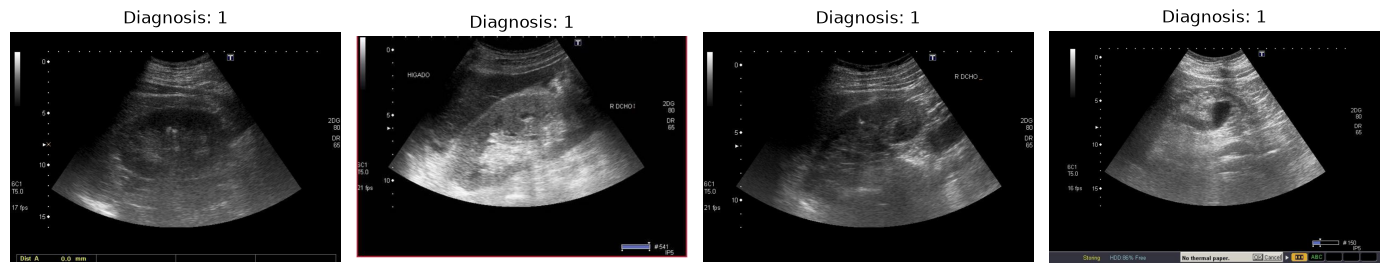

In [108]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, ax in enumerate(axes):
    img = Image.open(df.iloc[i]["image_path"])
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Diagnosis: {df.iloc[i]['diagnosis']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

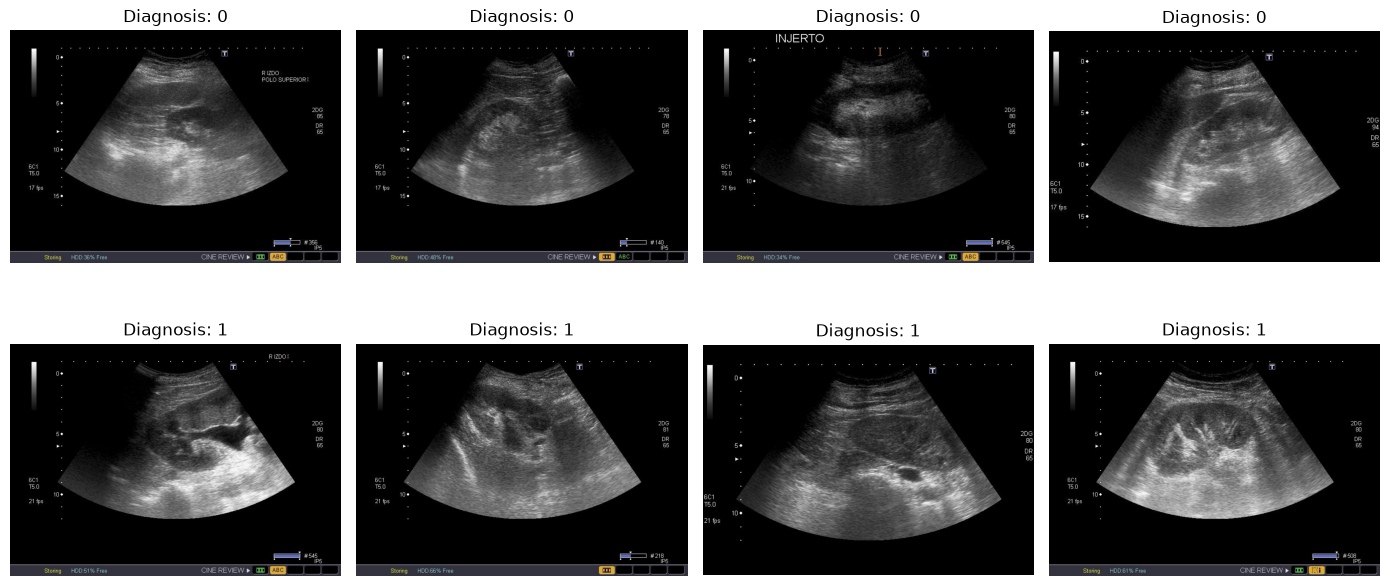

In [109]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, diagnosis in enumerate([0, 1]):

    samples = df[df["diagnosis"] == diagnosis].sample(
        n=4, random_state=42
    )

    for col, (_, sample) in enumerate(samples.iterrows()):

        img = Image.open(sample["image_path"])

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(
            f"Diagnosis: {diagnosis}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [110]:
image_sizes = []

for image_path in df["image_path"]:
    with Image.open(image_path) as img:
        image_sizes.append(img.size)

size_counts = Counter(image_sizes)

print("Number of unique image dimensions:", len(size_counts))
print("\nMost common image dimensions:")

for size, count in size_counts.most_common(10):
    print(f"{size}: {count} images")

Number of unique image dimensions: 18

Most common image dimensions:
(800, 561): 1742 images
(716, 498): 180 images
(716, 459): 48 images
(616, 412): 1 images
(576, 375): 1 images
(707, 508): 1 images
(669, 474): 1 images
(706, 502): 1 images
(727, 504): 1 images
(608, 463): 1 images


### Prepare for PyTorch

In [111]:
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Splitting the Dataset

Before training the CNN model, the dataset is divided into three subsets:

- **Training set (70%):** Used to train the CNN model.
- **Validation set (15%):** Used to monitor model performance and tune hyperparameters.
- **Testing set (15%):** Used for final model evaluation on unseen images.

#### Stratified Sampling

The dataset has an imbalanced class distribution, with 1,535 images belonging to class 1 and 450 images belonging to class 0.

To maintain the original class proportions across all three subsets, stratified sampling is applied using `train_test_split()` from Scikit-learn.

A fixed random state (`random_state=42`) is used to ensure reproducibility.

In [112]:
# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["diagnosis"]
)

# Second split: divide temporary data equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["diagnosis"]
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display split sizes
print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Testing set:", test_df.shape)

print("\nClass distribution in each split:")

for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}:")
    print(split["diagnosis"].value_counts())

Training set: (1389, 2)
Validation set: (298, 2)
Testing set: (298, 2)

Class distribution in each split:

Training:
diagnosis
1    1074
0     315
Name: count, dtype: int64

Validation:
diagnosis
1    231
0     67
Name: count, dtype: int64

Testing:
diagnosis
1    230
0     68
Name: count, dtype: int64


#### Dataset Split Summary

The dataset was successfully divided into training, validation, and testing subsets using stratified sampling.

| Subset | Percentage | Number of Images |
|---|---:|---:|
| Training | 70% | 1,389 |
| Validation | 15% | 298 |
| Testing | 15% | 298 |
| **Total** | **100%** | **1,985** |

The class distribution was maintained approximately across all three subsets.

This ensures that both classes are represented proportionally during model training, validation, and final evaluation.

The testing set will remain separate and will only be used for the final evaluation of the trained CNN model.

**Handling Class Distribution**

The dataset contains an imbalanced class distribution, with Class 0 representing 22.67% and Class 1 representing 77.33% of the images. Stratified sampling was used during dataset splitting to maintain approximately the same class proportions across the training, validation and testing sets.

## 3. CNN V1 – Baseline Model

### 3.1 Image Preprocessing and Transformations

Before feeding the ultrasound images into the CNN, they need to be converted into a consistent format and size.

The original images have different dimensions. Therefore, the following preprocessing operations are applied:

- **Image resizing:** Images are resized to 224 × 224 pixels.
- **Aspect ratio preservation:** Padding is used to maintain the original proportions and avoid distorting the ultrasound images.
- **RGB conversion:** Images are converted into three colour channels to maintain compatibility with commonly used CNN architectures.
- **Tensor conversion:** Images are converted into PyTorch tensors so they can be processed by the neural network.

The same basic preprocessing operations are applied to the training, validation, and testing datasets to ensure consistency.

In [113]:
IMG_SIZE = 224

class ResizeWithPadding:
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        return ImageOps.pad(
            image,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR,
            color=(0, 0, 0)
        )

train_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.ToTensor()
])

eval_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.ToTensor()
])

In [114]:
sample_path = train_df.loc[0, "image_path"]

original_image = Image.open(sample_path).convert("RGB")
processed_image = train_transform(original_image)

print("Original image size:", original_image.size)
print("Processed tensor shape:", processed_image.shape)
print("Pixel value range:",
      processed_image.min().item(),
      "to",
      processed_image.max().item())

Original image size: (800, 561)
Processed tensor shape: torch.Size([3, 224, 224])
Pixel value range: 0.0 to 0.9686274528503418


**Observations**

A sample image was resized to 224 × 224 pixels using padding to preserve its aspect ratio. The resulting tensor has three RGB channels, a shape of (3, 224, 224), and pixel values between 0 and 1.

### 3.2 Dataset and DataLoaders

A custom PyTorch Dataset is created to connect the image paths and diagnosis labels stored in the Pandas DataFrame.

This allows PyTorch to load images and labels efficiently during CNN training.

#### 3.2.1 Implement the Dataset class

In [115]:
class KidneyUltrasoundDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        image_path = self.dataframe.loc[index, "image_path"]
        label = self.dataframe.loc[index, "diagnosis"]

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing
        if self.transform:
            image = self.transform(image)

        # Convert label to tensor
        label = torch.tensor(label, dtype=torch.long)

        return image, label

#### 3.2.2 Create dataset objects

In [116]:
train_dataset = KidneyUltrasoundDataset(
    train_df,
    transform=train_transform
)

val_dataset = KidneyUltrasoundDataset(
    val_df,
    transform=eval_transform
)

test_dataset = KidneyUltrasoundDataset(
    test_df,
    transform=eval_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1389
Validation samples: 298
Testing samples: 298


#### Test one sample

In [117]:
sample_image, sample_label = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Label:", sample_label.item())
print("Image data type:", sample_image.dtype)
print("Label data type:", sample_label.dtype)

Image shape: torch.Size([3, 224, 224])
Label: 1
Image data type: torch.float32
Label data type: torch.int64


**Observations**

The custom Dataset returns each image as a float32 tensor of shape (3, 224, 224) and its label as an int64 tensor, ready for use with the CNN and Cross Entropy Loss.

#### 3.2.3 Create DataLoaders

In [118]:
BATCH_SIZE = 32

# Generator for reproducible training data shuffling
train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [119]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Batch size:", len(labels))

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Batch size: 32


**Observations**

The DataLoaders successfully return batches of 32 images with shape (32, 3, 224, 224) and 32 corresponding labels. Shuffling is enabled for training and disabled for validation and testing.

### 3.3 CNN Architecture

A Convolutional Neural Network (CNN) is used to extract spatial features from ultrasound images and classify them into two diagnosis categories.

The proposed baseline CNN consists of:

- Convolutional layers to extract image features.
- ReLU activation functions to introduce non-linearity.
- Max-pooling layers to reduce spatial dimensions.
- A fully connected layer to perform classification.
- An output layer to predict one of the two classes.

The model takes preprocessed RGB images of size 224 × 224 pixels as input and produces two output scores corresponding to the two diagnosis labels (0 and 1).

#### 3.3.1 CNN architecture

In [120]:
class KidneyCNN(nn.Module):

    def __init__(self):
        super(KidneyCNN, self).__init__()

        self.features = nn.Sequential(

            # Convolutional Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolutional Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolutional Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

#### 3.3.2 Create the model

In [121]:
# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reset random seed before model initialisation
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


model = KidneyCNN().to(device)

print("Device:", device)
print(model)

Device: cuda
KidneyCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


#### 3.3.3 Model Parameter Inspection

The model's trainable parameters are calculated to understand its size and complexity.

A forward pass is also performed using a sample batch to verify that the CNN produces the expected two-class output.

In [122]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 12,938,690
Trainable parameters: 12,938,690


#### 3.3.4 forward pass

In [123]:
model.eval()

with torch.no_grad():
    sample_images = images.to(device)
    outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("Device:", outputs.device)

model.train()

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 2])
Device: cuda:0


KidneyCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

**Observation**

The model contains 12,938,690 trainable parameters. A forward pass confirmed that it accepts a batch of 32 RGB images and returns two class scores per image.

### 3.4 Training Configuration

#### 3.4.1 Calculate class weights

**Handling Class Imbalance**

To address the class imbalance during model training, balanced class weights were calculated using the training dataset labels. A higher weight was assigned to the minority class so that misclassifications of Class 0 contribute more to the training loss.

The calculated weights were:

- Class 0: 2.2048
- Class 1: 0.6466

These weights were incorporated into the Cross Entropy Loss function and reused across CNN V1, V2 and V3.

In [124]:
classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"].values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)

Class weights: tensor([2.2048, 0.6466], device='cuda:0')


**Observation**

Class 0 receives a higher weight (2.2048) than Class 1 (0.6466), giving errors on the minority class greater influence in the training loss.

#### 3.4.2 Configure loss function and optimizer

In [125]:
# Loss function with class weights
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### 3.5 CNN Model Training

#### 3.5.1 Create the training function

In [126]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

#### 3.5.2 Create the validation function

In [127]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

#### 3.5.3 Training loop

The CNN is trained for a maximum of 20 epochs.

After each epoch, the model is evaluated using the validation dataset. Training and validation loss and accuracy are recorded to monitor learning progress and identify potential overfitting.

In [128]:
EPOCHS = 20

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Track the best model
v1_best_val_loss = float("inf")
v1_best_epoch = 0
v1_best_model_state = None

# Train CNN V1
for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    # Save best checkpoint
    if val_loss < v1_best_val_loss:

        v1_best_val_loss = val_loss
        v1_best_epoch = epoch + 1

        v1_best_model_state = copy.deepcopy(
            model.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

# Restore best model
model.load_state_dict(v1_best_model_state)

print("\nBest Model Selected")
print("Best Epoch:", v1_best_epoch)
print("Best Validation Loss:", round(v1_best_val_loss, 4))

Epoch [1/20] Train Loss: 0.7346 | Train Accuracy: 0.7401 | Val Loss: 0.6869 | Val Accuracy: 0.7752
Epoch [2/20] Train Loss: 0.7024 | Train Accuracy: 0.5918 | Val Loss: 0.6905 | Val Accuracy: 0.6846
Epoch [3/20] Train Loss: 0.6884 | Train Accuracy: 0.5738 | Val Loss: 0.6769 | Val Accuracy: 0.7215
Epoch [4/20] Train Loss: 0.6709 | Train Accuracy: 0.6458 | Val Loss: 0.6712 | Val Accuracy: 0.5772
Epoch [5/20] Train Loss: 0.6690 | Train Accuracy: 0.5673 | Val Loss: 0.6647 | Val Accuracy: 0.5268
Epoch [6/20] Train Loss: 0.6662 | Train Accuracy: 0.5947 | Val Loss: 0.6616 | Val Accuracy: 0.6477
Epoch [7/20] Train Loss: 0.6526 | Train Accuracy: 0.6487 | Val Loss: 0.6697 | Val Accuracy: 0.5235
Epoch [8/20] Train Loss: 0.6570 | Train Accuracy: 0.5623 | Val Loss: 0.6594 | Val Accuracy: 0.5940
Epoch [9/20] Train Loss: 0.6427 | Train Accuracy: 0.6400 | Val Loss: 0.6753 | Val Accuracy: 0.7114
Epoch [10/20] Train Loss: 0.6404 | Train Accuracy: 0.6638 | Val Loss: 0.6639 | Val Accuracy: 0.6946
Epoch [11

### 3.6 Training Performance Visualisation

Training and validation loss and accuracy are visualised across the 20 epochs.

These plots help assess whether the model is learning effectively, whether validation performance is improving, and whether there are signs of overfitting.

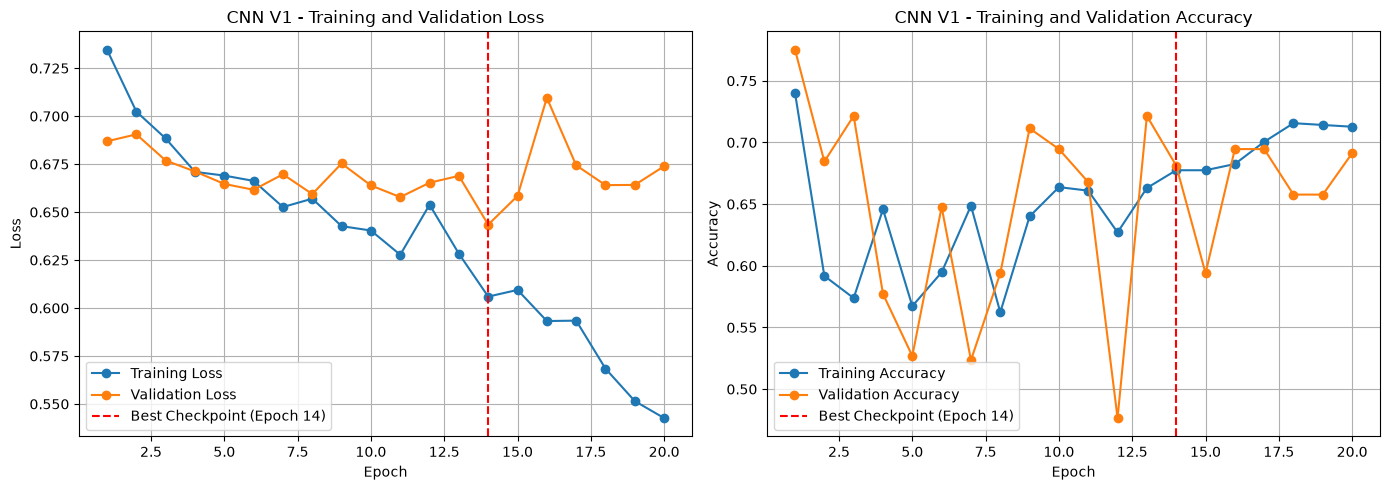

Best checkpoint epoch: 14
Best validation loss: 0.6435


In [129]:
epochs = range(1, EPOCHS + 1)

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training and validation loss
axes[0].plot(
    epochs, history["train_loss"],
    label="Training Loss", marker="o"
)

axes[0].plot(
    epochs, history["val_loss"],
    label="Validation Loss", marker="o"
)

axes[0].axvline(
    v1_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Checkpoint (Epoch {v1_best_epoch})"
)

axes[0].set_title("CNN V1 - Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Training and validation accuracy
axes[1].plot(
    epochs, history["train_accuracy"],
    label="Training Accuracy", marker="o"
)

axes[1].plot(
    epochs, history["val_accuracy"],
    label="Validation Accuracy", marker="o"
)

axes[1].axvline(
    v1_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Checkpoint (Epoch {v1_best_epoch})"
)

axes[1].set_title("CNN V1 - Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Best checkpoint epoch:", v1_best_epoch)
print("Best validation loss:", round(v1_best_val_loss, 4))

**Observations**

- Training loss decreased from 0.7346 to 0.5426, indicating that the CNN learned patterns from the training data.
- Training accuracy increased overall, finishing at 71.27%.
- Validation loss reached its lowest value of 0.6435 at epoch 14 before fluctuating during the remaining epochs.
- Validation accuracy fluctuated considerably, achieving its highest value of 77.52% at epoch 1 and finishing at 69.13%.
- The increasing gap between training and validation loss in later epochs suggests signs of overfitting.
- The best model checkpoint was selected at epoch 14 based on the lowest validation loss.

Overall, CNN V1 demonstrates learning progress, although its validation performance remains inconsistent.

### 3.7 Validation Evaluation

The trained CNN is evaluated using the validation dataset to assess its classification performance.

Since the dataset has an imbalanced class distribution, accuracy alone is not sufficient to evaluate the model.

The following evaluation metrics are used:

- **Confusion Matrix:** Examines correct and incorrect predictions for each class.
- **Precision:** Measures how many predicted samples for a class are correct.
- **Recall:** Measures how many actual samples of a class are correctly identified.
- **F1-score:** Provides a balance between precision and recall.
- **Balanced Accuracy:** Calculates the average recall across both classes.
- **ROC-AUC:** Measures the model's ability to distinguish between the two classes using prediction scores.

The evaluation focuses particularly on the minority class to determine whether the model can identify both diagnosis categories effectively.

#### 3.7.1 Generate Predictions

In [130]:
# Set model to evaluation mode
model.eval()

# Store predictions, actual labels and probabilities
all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert lists to NumPy arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
all_probabilities = np.array(all_probabilities)

# Display evaluation data information
print("Total validation samples:", len(all_labels))
print("Prediction shape:", all_predictions.shape)
print("Probability shape:", all_probabilities.shape)

# Check prediction distribution
unique_predictions, prediction_counts = np.unique(
    all_predictions,
    return_counts=True
)

print("\nPrediction distribution:")

for label, count in zip(unique_predictions, prediction_counts):
    print(f"Class {label}: {count} predictions")

Total validation samples: 298
Prediction shape: (298,)
Probability shape: (298, 2)

Prediction distribution:
Class 0: 104 predictions
Class 1: 194 predictions


#### 3.7.2 Calculate Evaluation Metrics

In [131]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Calculate evaluation metrics
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    all_labels, all_predictions
)

roc_auc = roc_auc_score(
    all_labels, all_probabilities[:, 1]
)

print("Validation Evaluation Metrics")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Weighted Precision:{precision:.4f}")
print(f"Weighted Recall:   {recall:.4f}")
print(f"Weighted F1-score: {f1:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")
print(f"ROC-AUC:           {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["Class 0", "Class 1"],
    zero_division=0
))

Validation Evaluation Metrics
Accuracy:          0.6812
Weighted Precision:0.7414
Weighted Recall:   0.6812
Weighted F1-score: 0.7018
Balanced Accuracy: 0.6407
ROC-AUC:           0.6778

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.37      0.57      0.44        67
     Class 1       0.85      0.71      0.78       231

    accuracy                           0.68       298
   macro avg       0.61      0.64      0.61       298
weighted avg       0.74      0.68      0.70       298



#### 3.7.3 Confusion Matrix

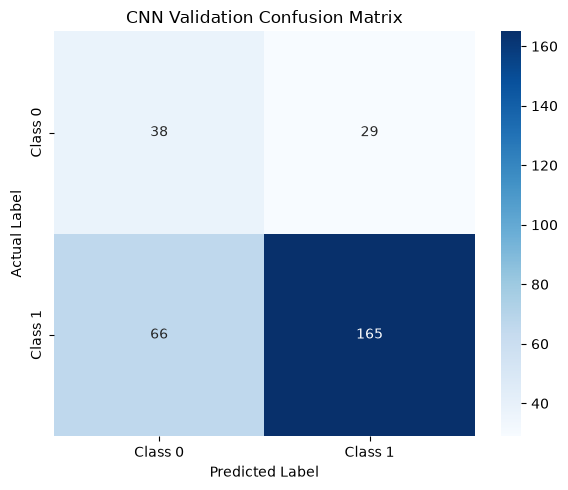

In [132]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Validation Confusion Matrix")

plt.tight_layout()
plt.show()

**Observations**

- CNN V1 achieved 68.12% accuracy, 70.18% weighted F1-score, 64.07% balanced accuracy and 67.78% ROC-AUC.
- Class 0 achieved 57% recall, while Class 1 achieved 71% recall.
- The confusion matrix shows that 203 out of 298 validation images were correctly classified.
- The model successfully identifies both classes, although its performance remains stronger for the majority class.
- The best model checkpoint was selected at epoch 14 based on the lowest validation loss of 0.6435.

Overall, CNN V1 provides a baseline for comparison with the improved preprocessing and architectural experiments.

## 4. CNN V2 – Improved Preprocessing

In this version, the preprocessing pipeline is improved
through image normalisation and data augmentation.

The CNN architecture, dataset split, training configuration
and random seed are kept consistent with CNN V1 to allow
a fair comparison.

### 4.1  Add V2 preprocessing

#### 4.1.1 Calculate training image mean and standard deviation

In [33]:
# Calculate normalisation statistics using training images only

base_transform_v2 = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.ToTensor()
])

channel_sum = torch.zeros(3, dtype=torch.float64)
channel_sum_sq = torch.zeros(3, dtype=torch.float64)
num_pixels = 0

for image_path in train_df["image_path"]:

    with Image.open(image_path) as img:
        image_tensor = base_transform_v2(img.convert("RGB")).double()

    channel_sum += image_tensor.sum(dim=(1, 2))
    channel_sum_sq += (image_tensor ** 2).sum(dim=(1, 2))

    num_pixels += image_tensor.shape[1] * image_tensor.shape[2]

mean_v2 = channel_sum / num_pixels

variance_v2 = (
    channel_sum_sq / num_pixels - mean_v2 ** 2
).clamp_min(1e-12)

std_v2 = torch.sqrt(variance_v2)

print("Mean:", mean_v2.tolist())
print("Standard Deviation:", std_v2.tolist())

Mean: [0.07053597763566266, 0.07038210061987563, 0.07113876770141754]
Standard Deviation: [0.149478900728274, 0.14892029067613985, 0.14955732687369758]


#### 4.1.2 Create V2 transformations

In [34]:
# CNN V2 preprocessing

train_transform_v2 = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean_v2.tolist(),
        std=std_v2.tolist()
    )
])

eval_transform_v2 = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean_v2.tolist(),
        std=std_v2.tolist()
    )
])

### 4.2 Dataset and DataLoaders

Separate PyTorch datasets and DataLoaders are created for CNN V2 using the improved preprocessing transformations.

The training dataset applies random augmentation and normalisation, while validation and testing datasets use deterministic preprocessing and normalisation.

#### 4.2.1 Create V2 datasets

In [35]:
v2_train_dataset = KidneyUltrasoundDataset(
    train_df,
    transform=train_transform_v2
)

v2_val_dataset = KidneyUltrasoundDataset(
    val_df,
    transform=eval_transform_v2
)

v2_test_dataset = KidneyUltrasoundDataset(
    test_df,
    transform=eval_transform_v2
)

print("V2 Training samples:", len(v2_train_dataset))
print("V2 Validation samples:", len(v2_val_dataset))
print("V2 Testing samples:", len(v2_test_dataset))

V2 Training samples: 1389
V2 Validation samples: 298
V2 Testing samples: 298


#### 4.2.2 Create V2 DataLoaders

In [36]:
BATCH_SIZE = 32

# Dedicated generator for reproducible V2 shuffling
v2_train_generator = torch.Generator()
v2_train_generator.manual_seed(SEED)

v2_train_loader = DataLoader(
    v2_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=v2_train_generator
)

v2_val_loader = DataLoader(
    v2_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

v2_test_loader = DataLoader(
    v2_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

#### 4.2.3 Check one training batch

In [37]:
v2_images, v2_labels = next(iter(v2_train_loader))

print("Batch image shape:", v2_images.shape)
print("Batch label shape:", v2_labels.shape)
print("Batch size:", len(v2_labels))
print("Images contain valid values:",
      torch.isfinite(v2_images).all().item())

# Reset generator after inspection
v2_train_generator.manual_seed(SEED)

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Batch size: 32
Images contain valid values: True


### 4.3 CNN Architecture

#### 4.3.1 Initialise a fresh V2 model

In [44]:
# Reproducible initialisation for CNN V2
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a fresh CNN V2 model
v2_model = KidneyCNN().to(device)

print("Device:", device)
print(v2_model)

Device: cuda
KidneyCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


#### 4.3.2 Check the model

In [45]:
total_params = sum(
    p.numel() for p in v2_model.parameters()
)

trainable_params = sum(
    p.numel() for p in v2_model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 12938690
Trainable parameters: 12938690


### 4.4 Training Configuration

The CNN V2 model uses the same class weights, loss function, optimiser and learning rate as CNN V1.

This ensures that the effect of improved image preprocessing and augmentation can be evaluated independently.

#### 4.4.1 Class weights

In [46]:
# Reuse the class weights calculated in V1
v2_class_weights = class_weights.clone()

print("V2 Class weights:", v2_class_weights)

V2 Class weights: tensor([2.2048, 0.6466], device='cuda:0')


#### 4.4.2 Loss function and optimiser

In [47]:
# Loss function with class weights
v2_criterion = nn.CrossEntropyLoss(
    weight=v2_class_weights
)

# Adam optimizer
v2_optimizer = torch.optim.Adam(
    v2_model.parameters(),
    lr=0.001
)

V2_EPOCHS = 20

print("Loss function:", v2_criterion)
print("Optimizer:", v2_optimizer)
print("Epochs:", V2_EPOCHS)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Epochs: 20


### 4.5 Model Training

The CNN V2 model is trained using the improved preprocessing pipeline, which includes image normalisation and mild random rotation augmentation.

The same training configuration as CNN V1 is maintained, including the loss function, optimiser, learning rate and number of epochs.

Training and validation performance are recorded for comparison.

In [48]:
import copy

# Reproducibility
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

v2_train_generator.manual_seed(SEED)

# Initialise training history
v2_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Track best model
best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

# Train CNN V2
for epoch in range(V2_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        v2_model,
        v2_train_loader,
        v2_criterion,
        v2_optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        v2_model,
        v2_val_loader,
        v2_criterion,
        device
    )

    v2_history["train_loss"].append(train_loss)
    v2_history["train_accuracy"].append(train_acc)
    v2_history["val_loss"].append(val_loss)
    v2_history["val_accuracy"].append(val_acc)

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(
            v2_model.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{V2_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

# Restore best model
v2_model.load_state_dict(best_model_state)

print("\nBest Model Selected")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", round(best_val_loss, 4))

Epoch [1/20] Train Loss: 0.9331 | Train Accuracy: 0.4852 | Val Loss: 0.6834 | Val Accuracy: 0.7282
Epoch [2/20] Train Loss: 0.6838 | Train Accuracy: 0.5580 | Val Loss: 0.6742 | Val Accuracy: 0.6409
Epoch [3/20] Train Loss: 0.6779 | Train Accuracy: 0.6199 | Val Loss: 0.6703 | Val Accuracy: 0.7416
Epoch [4/20] Train Loss: 0.6709 | Train Accuracy: 0.6199 | Val Loss: 0.6831 | Val Accuracy: 0.7282
Epoch [5/20] Train Loss: 0.6680 | Train Accuracy: 0.6156 | Val Loss: 0.6609 | Val Accuracy: 0.5906
Epoch [6/20] Train Loss: 0.6669 | Train Accuracy: 0.5940 | Val Loss: 0.6549 | Val Accuracy: 0.6711
Epoch [7/20] Train Loss: 0.6695 | Train Accuracy: 0.6919 | Val Loss: 0.6486 | Val Accuracy: 0.6544
Epoch [8/20] Train Loss: 0.6455 | Train Accuracy: 0.6595 | Val Loss: 0.6606 | Val Accuracy: 0.6812
Epoch [9/20] Train Loss: 0.6435 | Train Accuracy: 0.6595 | Val Loss: 0.6433 | Val Accuracy: 0.6879
Epoch [10/20] Train Loss: 0.6326 | Train Accuracy: 0.6609 | Val Loss: 0.6389 | Val Accuracy: 0.7584
Epoch [11

### 4.6 Training Performance Visualisation

The training and validation loss and accuracy are visualised
to examine the learning behaviour of CNN V2.

The best model checkpoint, selected using the lowest
validation loss, is also indicated in the plots.

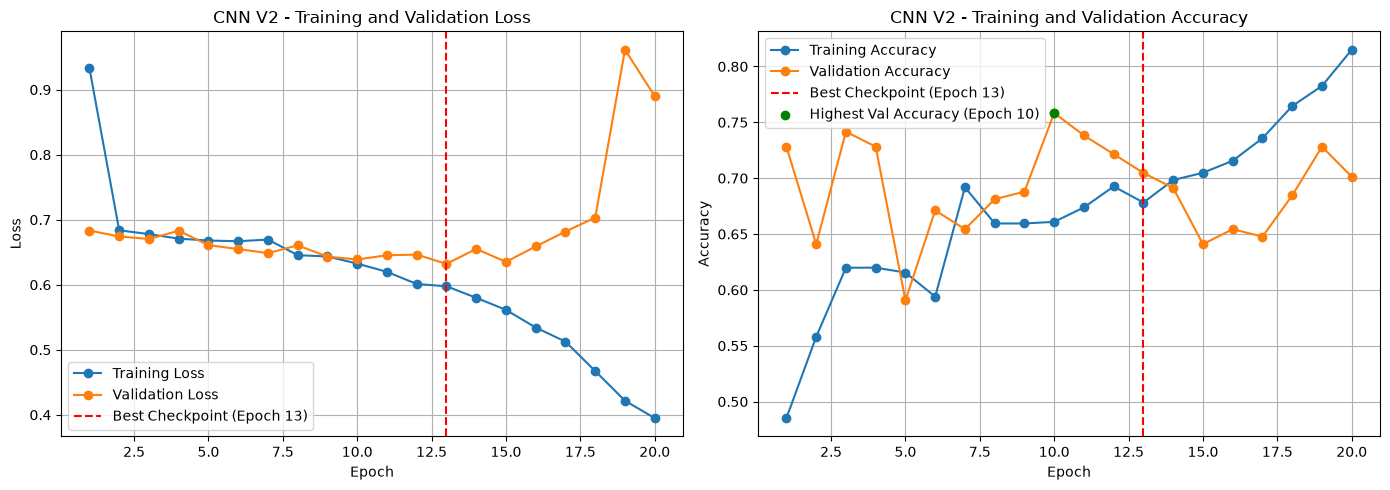

Best checkpoint epoch: 13
Best validation loss: 0.6321
Highest validation accuracy epoch: 10
Highest validation accuracy: 0.7584


In [49]:
# Epoch numbers
epochs = range(1, V2_EPOCHS + 1)

# Identify best validation accuracy
best_accuracy_epoch = (
    np.argmax(v2_history["val_accuracy"]) + 1
)

best_accuracy = max(v2_history["val_accuracy"])

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(
    epochs,
    v2_history["train_loss"],
    label="Training Loss",
    marker="o"
)

axes[0].plot(
    epochs,
    v2_history["val_loss"],
    label="Validation Loss",
    marker="o"
)

axes[0].axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Checkpoint (Epoch {best_epoch})"
)

axes[0].set_title("CNN V2 - Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy plot
axes[1].plot(
    epochs,
    v2_history["train_accuracy"],
    label="Training Accuracy",
    marker="o"
)

axes[1].plot(
    epochs,
    v2_history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

axes[1].axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Checkpoint (Epoch {best_epoch})"
)

axes[1].scatter(
    best_accuracy_epoch,
    best_accuracy,
    color="green",
    zorder=5,
    label=f"Highest Val Accuracy (Epoch {best_accuracy_epoch})"
)

axes[1].set_title("CNN V2 - Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Best checkpoint epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Highest validation accuracy epoch:", best_accuracy_epoch)
print("Highest validation accuracy:", round(best_accuracy, 4))

**Observations**

- Training loss decreased consistently from 0.9331 in the first epoch to 0.3950 in the final epoch, indicating that the model progressively learned patterns from the training data.
- Training accuracy increased from 48.52% to 81.50% across the 20 epochs.
- Validation loss fluctuated throughout training and reached its lowest value of 0.6321 at epoch 13. After this point, validation loss generally increased, reaching 0.8900 by epoch 20.
- Validation accuracy fluctuated considerably, achieving its highest value of 75.84% at epoch 10 before finishing at 70.13%.
- A noticeable gap developed between training and validation performance during the later epochs. While training loss continued to decrease and training accuracy increased, validation performance did not improve consistently.
- These trends suggest overfitting, particularly after epoch 13, as the model continued improving on the training data without corresponding improvements on the validation data.

**Best Model Selection:**

- The best model checkpoint was selected at epoch 13 based on the lowest validation loss of 0.6321.
- Although epoch 10 achieved the highest validation accuracy of 75.84%, epoch 13 was selected because validation loss was used as the checkpoint selection criterion.

Overall, CNN V2 demonstrates improved learning behaviour, but the validation curves indicate that further optimisation is required to improve generalisation.

### 4.7 Validation Evaluation

CNN V2 is evaluated using the validation dataset to assess its classification performance.

The evaluation uses accuracy, precision, recall, F1-score, balanced accuracy and ROC-AUC. A confusion matrix and classification report are also generated to examine class-wise performance.

The best model checkpoint, selected using the lowest validation loss, is used for evaluation.

#### 4.7.1 Generate predictions

In [50]:
# Set V2 model to evaluation mode
v2_model.eval()

# Store predictions, actual labels and probabilities
v2_all_predictions = []
v2_all_labels = []
v2_all_probabilities = []

with torch.no_grad():

    for images, labels in v2_val_loader:

        images = images.to(device)

        outputs = v2_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        v2_all_predictions.extend(predictions.cpu().numpy())
        v2_all_labels.extend(labels.numpy())
        v2_all_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy arrays
v2_all_predictions = np.array(v2_all_predictions)
v2_all_labels = np.array(v2_all_labels)
v2_all_probabilities = np.array(v2_all_probabilities)

print("Total validation samples:", len(v2_all_labels))
print("Prediction shape:", v2_all_predictions.shape)
print("Probability shape:", v2_all_probabilities.shape)

# Prediction distribution
unique_predictions, prediction_counts = np.unique(
    v2_all_predictions,
    return_counts=True
)

print("\nV2 Prediction Distribution:")

for label, count in zip(unique_predictions, prediction_counts):
    print(f"Class {label}: {count} predictions")

Total validation samples: 298
Prediction shape: (298,)
Probability shape: (298, 2)

V2 Prediction Distribution:
Class 0: 99 predictions
Class 1: 199 predictions


#### 4.7.2 Calculate evaluation metrics

In [51]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Calculate metrics
v2_accuracy = accuracy_score(
    v2_all_labels, v2_all_predictions
)

v2_precision = precision_score(
    v2_all_labels, v2_all_predictions,
    average="weighted",
    zero_division=0
)

v2_recall = recall_score(
    v2_all_labels, v2_all_predictions,
    average="weighted",
    zero_division=0
)

v2_f1 = f1_score(
    v2_all_labels, v2_all_predictions,
    average="weighted",
    zero_division=0
)

v2_balanced_acc = balanced_accuracy_score(
    v2_all_labels, v2_all_predictions
)

v2_roc_auc = roc_auc_score(
    v2_all_labels, v2_all_probabilities[:, 1]
)

print("CNN V2 Validation Evaluation Metrics")
print(f"Accuracy:           {v2_accuracy:.4f}")
print(f"Weighted Precision: {v2_precision:.4f}")
print(f"Weighted Recall:    {v2_recall:.4f}")
print(f"Weighted F1-score:  {v2_f1:.4f}")
print(f"Balanced Accuracy:  {v2_balanced_acc:.4f}")
print(f"ROC-AUC:            {v2_roc_auc:.4f}")

print("\nV2 Classification Report:")

print(classification_report(
    v2_all_labels,
    v2_all_predictions,
    labels=[0, 1],
    target_names=["Class 0", "Class 1"],
    zero_division=0
))

CNN V2 Validation Evaluation Metrics
Accuracy:           0.7047
Weighted Precision: 0.7547
Weighted Recall:    0.7047
Weighted F1-score:  0.7222
Balanced Accuracy:  0.6612
ROC-AUC:            0.6907

V2 Classification Report:
              precision    recall  f1-score   support

     Class 0       0.39      0.58      0.47        67
     Class 1       0.86      0.74      0.80       231

    accuracy                           0.70       298
   macro avg       0.63      0.66      0.63       298
weighted avg       0.75      0.70      0.72       298



#### 4.7.3 Generate confusion matrix

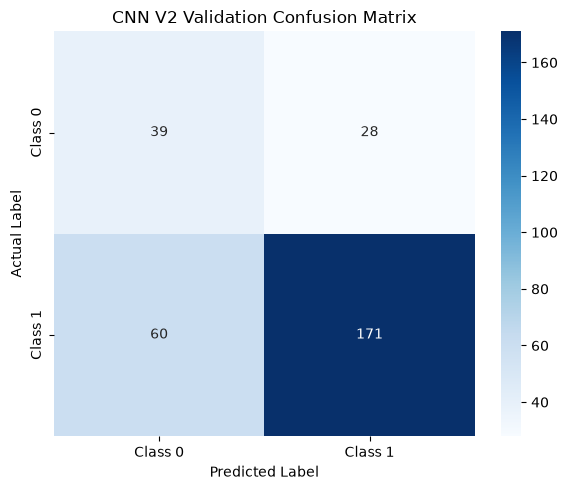

In [52]:
v2_cm = confusion_matrix(
    v2_all_labels,
    v2_all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    v2_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN V2 Validation Confusion Matrix")

plt.tight_layout()
plt.show()

**Observations**

CNN V2 was evaluated on 298 validation images and achieved the following results:

- Accuracy: 70.47%
- Weighted Precision: 75.47%
- Weighted Recall: 70.47%
- Weighted F1-score: 72.22%
- Balanced Accuracy: 66.12%
- ROC-AUC: 69.07%

## 5. CNN V3 – Architecture Improvements

CNN V3 introduces architectural improvements to the baseline CNN.

Batch Normalisation and Adaptive Average Pooling are introduced
to improve training stability and reduce model complexity.

The preprocessing pipeline from CNN V2 is retained to evaluate
the effect of architectural changes.

### 5.1 CNN V3 Architecture

In [53]:
class KidneyCNN_V3(nn.Module):

    def __init__(self):
        super(KidneyCNN_V3, self).__init__()

        self.features = nn.Sequential(

            # Convolutional Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolutional Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolutional Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Adaptive Average Pooling
        self.avgpool = nn.AdaptiveAvgPool2d((4, 4))

        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.avgpool(x)
        x = self.classifier(x)

        return x

#### 5.1.1 Test the Architecture

In [54]:
# Create a temporary V3 model
v3_test_model = KidneyCNN_V3().to(device)

# Test with a batch of images
dummy_input = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)

output = v3_test_model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

# Count parameters
total_params = sum(
    p.numel() for p in v3_test_model.parameters()
)

trainable_params = sum(
    p.numel() for p in v3_test_model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 2])
Total parameters: 356002
Trainable parameters: 356002


### 5.2 V3 Model Initialisation

In [55]:
# Set random seed
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a fresh CNN V3 model
v3_model = KidneyCNN_V3().to(device)

print("Device:", device)
print(v3_model)

Device: cuda
KidneyCNN_V3(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end

#### Verify trainable parameters

In [56]:
total_params = sum(
    p.numel() for p in v3_model.parameters()
)

trainable_params = sum(
    p.numel() for p in v3_model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 356002
Trainable parameters: 356002


### 5.3 Training Configuration

CNN V3 uses the same class weights, loss function, optimiser,
learning rate and number of epochs as CNN V2.

This maintains consistency between experiments and allows
the impact of architectural improvements to be evaluated.

In [57]:
# Reuse V2 class weights
v3_class_weights = v2_class_weights.clone().to(device)

# Weighted Cross Entropy Loss
v3_criterion = nn.CrossEntropyLoss(
    weight=v3_class_weights
)

# Adam Optimizer
v3_optimizer = torch.optim.Adam(
    v3_model.parameters(),
    lr=0.001
)

V3_EPOCHS = 20

print("Class weights:", v3_class_weights)
print("Loss function:", v3_criterion)
print("Optimizer:", v3_optimizer)
print("Epochs:", V3_EPOCHS)

Class weights: tensor([2.2048, 0.6466], device='cuda:0')
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Epochs: 20


### 5.4 Dataset and DataLoaders

CNN V3 reuses the datasets and DataLoaders created for CNN V2.

The same training, validation and testing splits are maintained, along with the improved preprocessing and augmentation pipeline.

In [58]:
# Reuse V2 datasets and DataLoaders
v3_train_loader = v2_train_loader
v3_val_loader = v2_val_loader
v3_test_loader = v2_test_loader

print("Training samples:", len(v3_train_loader.dataset))
print("Validation samples:", len(v3_val_loader.dataset))
print("Testing samples:", len(v3_test_loader.dataset))

Training samples: 1389
Validation samples: 298
Testing samples: 298


### 5.5 Model Training

CNN V3 is trained using the improved preprocessing pipeline from CNN V2 and the modified CNN architecture.

The model uses Batch Normalisation and Adaptive Average Pooling to improve feature extraction and reduce the number of trainable parameters.

The same training configuration is maintained, and the best model checkpoint is selected based on the lowest validation loss.

In [59]:
import copy

# Set random seeds for reproducibility
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Reset training DataLoader generator
v2_train_generator.manual_seed(SEED)

# Initialise V3 training history
v3_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Track best model
v3_best_val_loss = float("inf")
v3_best_epoch = 0
v3_best_model_state = None

# Train CNN V3
for epoch in range(V3_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        v3_model,
        v3_train_loader,
        v3_criterion,
        v3_optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        v3_model,
        v3_val_loader,
        v3_criterion,
        device
    )

    # Store metrics
    v3_history["train_loss"].append(train_loss)
    v3_history["train_accuracy"].append(train_acc)
    v3_history["val_loss"].append(val_loss)
    v3_history["val_accuracy"].append(val_acc)

    # Save best checkpoint
    if val_loss < v3_best_val_loss:
        v3_best_val_loss = val_loss
        v3_best_epoch = epoch + 1

        v3_best_model_state = copy.deepcopy(
            v3_model.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{V3_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

# Restore best model
v3_model.load_state_dict(v3_best_model_state)

print("\nBest Model Selected")
print("Best Epoch:", v3_best_epoch)
print("Best Validation Loss:", round(v3_best_val_loss, 4))

Epoch [1/20] Train Loss: 0.7266 | Train Accuracy: 0.5126 | Val Loss: 0.6863 | Val Accuracy: 0.7584
Epoch [2/20] Train Loss: 0.6972 | Train Accuracy: 0.5659 | Val Loss: 0.6841 | Val Accuracy: 0.5604
Epoch [3/20] Train Loss: 0.6850 | Train Accuracy: 0.5443 | Val Loss: 0.6809 | Val Accuracy: 0.6846
Epoch [4/20] Train Loss: 0.6796 | Train Accuracy: 0.5637 | Val Loss: 0.6805 | Val Accuracy: 0.5537
Epoch [5/20] Train Loss: 0.6889 | Train Accuracy: 0.5565 | Val Loss: 0.6814 | Val Accuracy: 0.5436
Epoch [6/20] Train Loss: 0.6828 | Train Accuracy: 0.5522 | Val Loss: 0.6821 | Val Accuracy: 0.5134
Epoch [7/20] Train Loss: 0.6820 | Train Accuracy: 0.5839 | Val Loss: 0.6801 | Val Accuracy: 0.5369
Epoch [8/20] Train Loss: 0.6769 | Train Accuracy: 0.5832 | Val Loss: 0.6799 | Val Accuracy: 0.5470
Epoch [9/20] Train Loss: 0.6801 | Train Accuracy: 0.5515 | Val Loss: 0.6775 | Val Accuracy: 0.6141
Epoch [10/20] Train Loss: 0.6802 | Train Accuracy: 0.5572 | Val Loss: 0.6758 | Val Accuracy: 0.6242
Epoch [11

### 5.6 Training Performance Visualisation

The training and validation loss and accuracy are visualised
to examine the learning behaviour of CNN V3.

The best model checkpoint, selected using the lowest
validation loss, is highlighted in the plots.

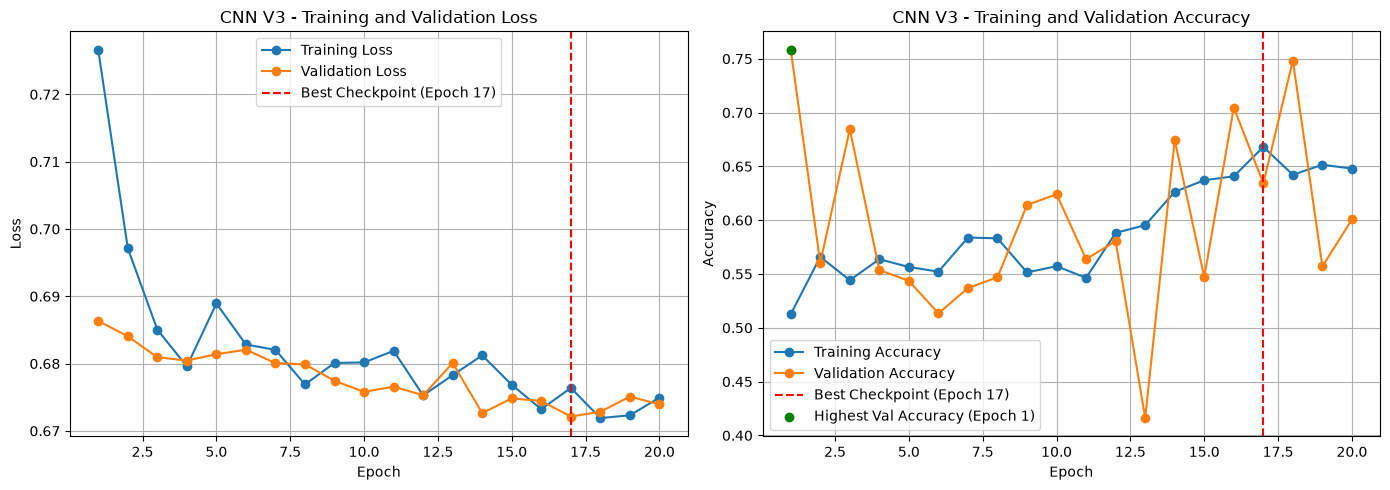

Best checkpoint epoch: 17
Best validation loss: 0.6721
Highest validation accuracy epoch: 1
Highest validation accuracy: 0.7584


In [60]:
# Epoch numbers
epochs = range(1, V3_EPOCHS + 1)

# Identify best validation accuracy
v3_best_accuracy_epoch = (
    np.argmax(v3_history["val_accuracy"]) + 1
)

v3_best_accuracy = max(v3_history["val_accuracy"])

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(
    epochs,
    v3_history["train_loss"],
    label="Training Loss",
    marker="o"
)

axes[0].plot(
    epochs,
    v3_history["val_loss"],
    label="Validation Loss",
    marker="o"
)

axes[0].axvline(
    v3_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Checkpoint (Epoch {v3_best_epoch})"
)

axes[0].set_title("CNN V3 - Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy plot
axes[1].plot(
    epochs,
    v3_history["train_accuracy"],
    label="Training Accuracy",
    marker="o"
)

axes[1].plot(
    epochs,
    v3_history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

axes[1].axvline(
    v3_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Checkpoint (Epoch {v3_best_epoch})"
)

axes[1].scatter(
    v3_best_accuracy_epoch,
    v3_best_accuracy,
    color="green",
    zorder=5,
    label=f"Highest Val Accuracy (Epoch {v3_best_accuracy_epoch})"
)

axes[1].set_title("CNN V3 - Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Best checkpoint epoch:", v3_best_epoch)
print("Best validation loss:", round(v3_best_val_loss, 4))
print("Highest validation accuracy epoch:", v3_best_accuracy_epoch)
print("Highest validation accuracy:", round(v3_best_accuracy, 4))

**Observations**

- Training loss decreased from 0.7266 to 0.6749, while training accuracy increased from 51.26% to 64.79%.
- Validation loss remained relatively stable and reached its lowest value of 0.6721 at epoch 17.
- Validation accuracy fluctuated considerably, achieving its highest value of 75.84% at epoch 1 before finishing at 60.07%.
- The model showed limited and inconsistent learning progress, suggesting that the smaller architecture may have reduced its ability to learn useful image features.
- The best checkpoint was selected at epoch 17 based on the lowest validation loss.

Overall, V3 has a substantially smaller architecture, but its training curves do not yet demonstrate improved generalisation.

### 5.7 Validation Evaluation

CNN V3 is evaluated using the validation dataset to assess its classification performance.

The evaluation includes accuracy, precision, recall, F1-score, balanced accuracy and ROC-AUC, along with a confusion matrix and classification report.

In [61]:
# Set V3 model to evaluation mode
v3_model.eval()

v3_all_predictions = []
v3_all_labels = []
v3_all_probabilities = []

with torch.no_grad():

    for images, labels in v3_val_loader:

        images = images.to(device)

        outputs = v3_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        v3_all_predictions.extend(predictions.cpu().numpy())
        v3_all_labels.extend(labels.numpy())
        v3_all_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy arrays
v3_all_predictions = np.array(v3_all_predictions)
v3_all_labels = np.array(v3_all_labels)
v3_all_probabilities = np.array(v3_all_probabilities)

print("Total validation samples:", len(v3_all_labels))

print("\nV3 Prediction Distribution:")

unique_predictions, prediction_counts = np.unique(
    v3_all_predictions,
    return_counts=True
)

for label, count in zip(unique_predictions, prediction_counts):
    print(f"Class {label}: {count} predictions")

Total validation samples: 298

V3 Prediction Distribution:
Class 0: 102 predictions
Class 1: 196 predictions


In [62]:
# Calculate evaluation metrics
v3_accuracy = accuracy_score(
    v3_all_labels, v3_all_predictions
)

v3_precision = precision_score(
    v3_all_labels, v3_all_predictions,
    average="weighted", zero_division=0
)

v3_recall = recall_score(
    v3_all_labels, v3_all_predictions,
    average="weighted", zero_division=0
)

v3_f1 = f1_score(
    v3_all_labels, v3_all_predictions,
    average="weighted", zero_division=0
)

v3_balanced_acc = balanced_accuracy_score(
    v3_all_labels, v3_all_predictions
)

v3_roc_auc = roc_auc_score(
    v3_all_labels, v3_all_probabilities[:, 1]
)

print("CNN V3 Validation Evaluation Metrics")
print(f"Accuracy:           {v3_accuracy:.4f}")
print(f"Weighted Precision: {v3_precision:.4f}")
print(f"Weighted Recall:    {v3_recall:.4f}")
print(f"Weighted F1-score:  {v3_f1:.4f}")
print(f"Balanced Accuracy:  {v3_balanced_acc:.4f}")
print(f"ROC-AUC:            {v3_roc_auc:.4f}")

print("\nV3 Classification Report:")

print(classification_report(
    v3_all_labels,
    v3_all_predictions,
    labels=[0, 1],
    target_names=["Class 0", "Class 1"],
    zero_division=0
))

CNN V3 Validation Evaluation Metrics
Accuracy:           0.6342
Weighted Precision: 0.6950
Weighted Recall:    0.6342
Weighted F1-score:  0.6571
Balanced Accuracy:  0.5680
ROC-AUC:            0.6134

V3 Classification Report:
              precision    recall  f1-score   support

     Class 0       0.29      0.45      0.36        67
     Class 1       0.81      0.69      0.74       231

    accuracy                           0.63       298
   macro avg       0.55      0.57      0.55       298
weighted avg       0.69      0.63      0.66       298



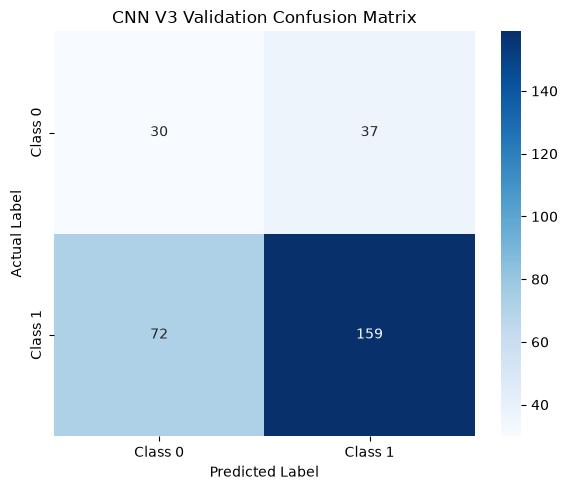

In [63]:
v3_cm = confusion_matrix(
    v3_all_labels,
    v3_all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    v3_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN V3 Validation Confusion Matrix")

plt.tight_layout()
plt.show()

**Observations**

- CNN V3 achieved 63.42% accuracy, 65.71% weighted F1-score, 56.80% balanced accuracy and 61.34% ROC-AUC.
- Class 0 achieved 45% recall, while Class 1 achieved 69% recall.
- The confusion matrix shows that 189 out of 298 validation images were correctly classified.
- Compared with V2, V3 showed a decline across all major evaluation metrics, suggesting that the reduced model complexity may have limited its ability to learn useful image features.
- Overall, the architectural changes did not improve classification performance. CNN V2 currently provides the best validation results.

## 6. CNN Performance Comparison

The validation performance of CNN V1, V2 and V3 is compared
using accuracy, weighted F1-score, balanced accuracy and ROC-AUC.

The comparison highlights the impact of improved preprocessing
and architectural changes on classification performance.

### 6.1 Create the comparison table

In [133]:
comparison_df = pd.DataFrame({
    "Model": ["CNN V1", "CNN V2", "CNN V3"],
    "Accuracy": [68.12, 70.47, 63.42],
    "Weighted F1": [70.18, 72.22, 65.71],
    "Balanced Accuracy": [64.07, 66.12, 56.80],
    "ROC-AUC": [67.78, 69.07, 61.34],
    "Class 0 Recall": [57, 58, 45],
    "Class 1 Recall": [71, 74, 69]
})

comparison_df

,Model,Accuracy,Weighted F1,Balanced Accuracy,ROC-AUC,Class 0 Recall,Class 1 Recall
0,CNN V1,68.12,70.18,64.07,67.78,57,71
1,CNN V2,70.47,72.22,66.12,69.07,58,74
2,CNN V3,63.42,65.71,56.80,61.34,45,69


### 6.2 Visualise model performance

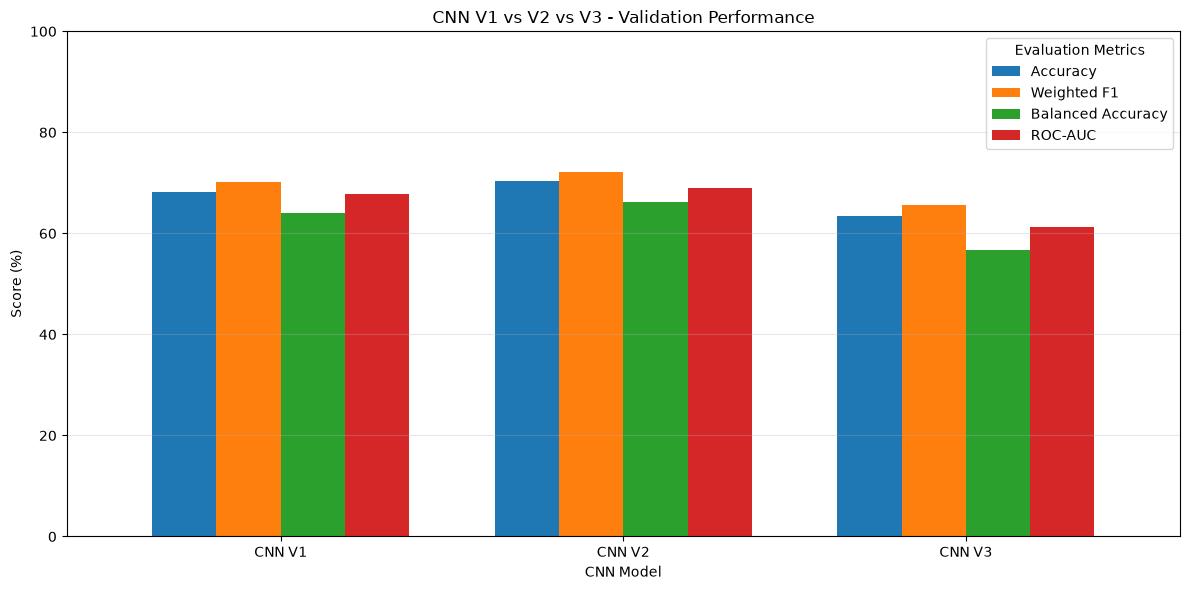

In [134]:
metrics = [
    "Accuracy",
    "Weighted F1",
    "Balanced Accuracy",
    "ROC-AUC"
]

ax = comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title("CNN V1 vs V2 vs V3 - Validation Performance")
ax.set_xlabel("CNN Model")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.legend(title="Evaluation Metrics")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.3 Compare class-wise recall

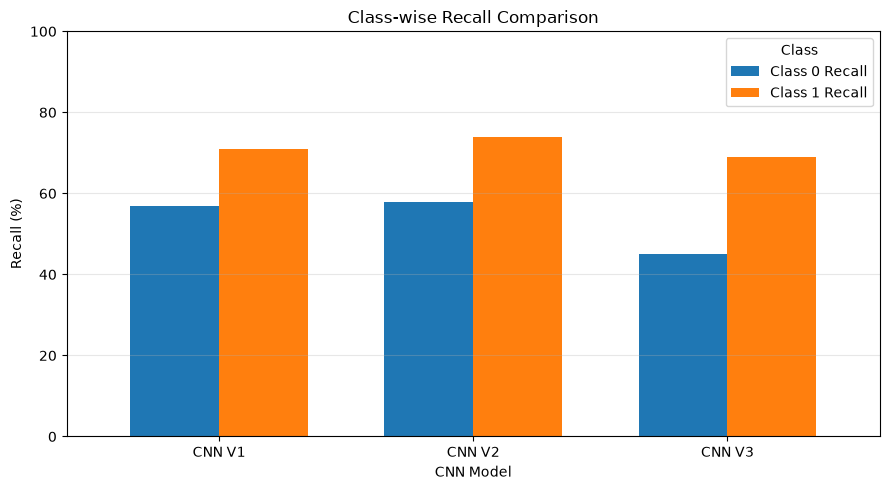

In [135]:
recall_metrics = [
    "Class 0 Recall",
    "Class 1 Recall"
]

ax = comparison_df.set_index("Model")[recall_metrics].plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

ax.set_title("Class-wise Recall Comparison")
ax.set_xlabel("CNN Model")
ax.set_ylabel("Recall (%)")
ax.set_ylim(0, 100)
ax.legend(title="Class")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observations**

- CNN V2 achieved the best overall validation performance, with 70.47% accuracy, 72.22% weighted F1-score, 66.12% balanced accuracy and 69.07% ROC-AUC.
- CNN V2 achieved the highest recall for both Class 0 (58%) and Class 1 (74%).
- CNN V1 showed comparable performance, while CNN V3 achieved the lowest results across all evaluation metrics.
- Overall, improved preprocessing and data augmentation in CNN V2 produced the best classification performance among the three experiments.

## 7. Final Model Selection and Independent Test Evaluation

CNN V2 was selected as the final model based on its validation
performance across the three CNN experiments.

The selected model is evaluated on the independent test dataset
to assess its final classification performance.

In [67]:
# Save the best CNN V2 model
torch.save(
    v2_model.state_dict(),
    "cnn_v2_best.pth"
)

print("CNN V2 best model saved successfully.")

CNN V2 best model saved successfully.


### 7.1 Independent Test Evaluation

In [68]:
# Evaluate CNN V2 on the independent test dataset
v2_model.eval()

v2_test_predictions = []
v2_test_labels = []
v2_test_probabilities = []

with torch.no_grad():

    for images, labels in v2_test_loader:

        images = images.to(device)

        outputs = v2_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        v2_test_predictions.extend(predictions.cpu().numpy())
        v2_test_labels.extend(labels.numpy())
        v2_test_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy arrays
v2_test_predictions = np.array(v2_test_predictions)
v2_test_labels = np.array(v2_test_labels)
v2_test_probabilities = np.array(v2_test_probabilities)

print("Total test samples:", len(v2_test_labels))

print("\nTest Prediction Distribution:")

unique_predictions, prediction_counts = np.unique(
    v2_test_predictions,
    return_counts=True
)

for label, count in zip(unique_predictions, prediction_counts):
    print(f"Class {label}: {count} predictions")

Total test samples: 298

Test Prediction Distribution:
Class 0: 98 predictions
Class 1: 200 predictions


In [69]:
v2_test_accuracy = accuracy_score(
    v2_test_labels, v2_test_predictions
)

v2_test_precision = precision_score(
    v2_test_labels, v2_test_predictions,
    average="weighted", zero_division=0
)

v2_test_recall = recall_score(
    v2_test_labels, v2_test_predictions,
    average="weighted", zero_division=0
)

v2_test_f1 = f1_score(
    v2_test_labels, v2_test_predictions,
    average="weighted", zero_division=0
)

v2_test_balanced_acc = balanced_accuracy_score(
    v2_test_labels, v2_test_predictions
)

v2_test_roc_auc = roc_auc_score(
    v2_test_labels, v2_test_probabilities[:, 1]
)

print("CNN V2 Independent Test Evaluation")
print(f"Accuracy:           {v2_test_accuracy:.4f}")
print(f"Weighted Precision: {v2_test_precision:.4f}")
print(f"Weighted Recall:    {v2_test_recall:.4f}")
print(f"Weighted F1-score:  {v2_test_f1:.4f}")
print(f"Balanced Accuracy:  {v2_test_balanced_acc:.4f}")
print(f"ROC-AUC:            {v2_test_roc_auc:.4f}")

print("\nClassification Report:")

print(classification_report(
    v2_test_labels,
    v2_test_predictions,
    labels=[0, 1],
    target_names=["Class 0", "Class 1"],
    zero_division=0
))

CNN V2 Independent Test Evaluation
Accuracy:           0.6711
Weighted Precision: 0.7198
Weighted Recall:    0.6711
Weighted F1-score:  0.6894
Balanced Accuracy:  0.6109
ROC-AUC:            0.6758

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.35      0.50      0.41        68
     Class 1       0.83      0.72      0.77       230

    accuracy                           0.67       298
   macro avg       0.59      0.61      0.59       298
weighted avg       0.72      0.67      0.69       298



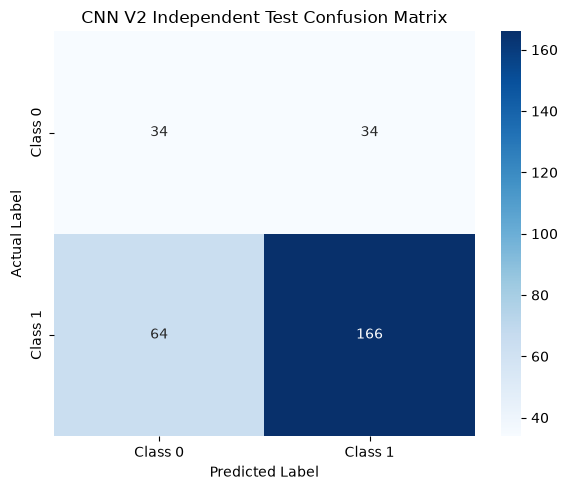

In [70]:
v2_test_cm = confusion_matrix(
    v2_test_labels,
    v2_test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    v2_test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN V2 Independent Test Confusion Matrix")

plt.tight_layout()
plt.show()

**Observations**

- CNN V2 achieved 67.11% test accuracy, 68.94% weighted F1-score, 61.09% balanced accuracy and 67.58% ROC-AUC.
- Class 0 achieved 50% recall, while Class 1 achieved 72% recall.
- The confusion matrix shows that 200 out of 298 test images were correctly classified.
- Test accuracy was slightly lower than validation accuracy (70.47%), indicating a reduction in performance on unseen data.
- Although the model identifies both classes, its test accuracy is below the 77.18% majority-class baseline, highlighting limitations in overall classification performance.

Overall, CNN V2 demonstrates some ability to identify minority-class images, but further improvements are needed to achieve better classification performance.

## References

- Molina-Moreno, M., González-Díaz, I., Rivera Gorrín, M., Burguera Vion, V. and Díaz-de-María, F. (2024) ‘URI-CADS: A fully automated computer-aided diagnosis system for ultrasound renal imaging’, *Journal of Imaging Informatics in Medicine*, 37(4), pp. 1458–1474. Available at: https://doi.org/10.1007/s10278-024-01055-4 .

- *URI-CAD renal ultrasound dataset* (n.d.) [Dataset]. Available at: https://doi.org/10.21950/0E0CTF .